# LAB 04 — Text Classification

## Experiment 1 — Dataset Inspection
Khảo sát tập dữ liệu IMDb (Large Movie Review Dataset) trước khi huấn luyện mô hình:
- Phân phối nhãn (Class distribution)
- Dữ liệu khuyết thiếu (Missing text & labels)
- Trùng lặp văn bản (Duplicate documents)
- Thống kê độ dài văn bản (Document length)


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def load_imdb(split, base_dir="datasets/aclImdb"):
    if not os.path.exists(base_dir) and os.path.exists(os.path.join("lab04", base_dir)):
        base_dir = os.path.join("lab04", base_dir)
    data = []
    for label in ["pos", "neg"]:
        folder = os.path.join(base_dir, split, label)
        for fname in os.listdir(folder):
            if fname.endswith(".txt"):
                fpath = os.path.join(folder, fname)
                with open(fpath, "r", encoding="utf-8") as f:
                    text = f.read()
                data.append({"text": text, "label": label})
    return pd.DataFrame(data)

df_train = load_imdb("train")
df_test = load_imdb("test")

print("Train:", len(df_train))
print("Test:", len(df_test))


Train: 25000
Test: 25000


### 1. Phân phối nhãn (Class Distribution)

,Train Count,Train %,Test Count,Test %
label,,,,
pos,12500,50.0,12500,50.0
neg,12500,50.0,12500,50.0


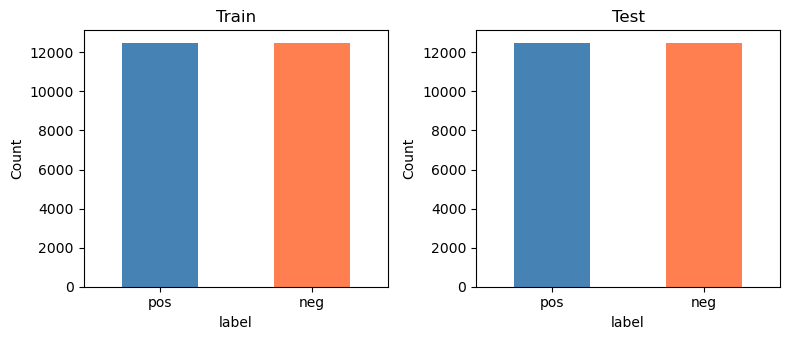

In [2]:
train_counts = df_train["label"].value_counts()
test_counts = df_test["label"].value_counts()

dist_df = pd.DataFrame({
    "Train Count": train_counts,
    "Train %": train_counts / len(df_train) * 100,
    "Test Count": test_counts,
    "Test %": test_counts / len(df_test) * 100
})
display(dist_df)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
train_counts.plot(kind="bar", ax=axes[0], color=["steelblue", "coral"], rot=0)
axes[0].set_title("Train")
axes[0].set_ylabel("Count")

test_counts.plot(kind="bar", ax=axes[1], color=["steelblue", "coral"], rot=0)
axes[1].set_title("Test")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


**Nhận xét:**
- Tập dữ liệu cân bằng hoàn hảo (balanced): cả tập Train và Test đều có chính xác 12,500 mẫu `pos` (50%) và 12,500 mẫu `neg` (50%).
- Dataset không bị class imbalance. Do đó metric Accuracy hoàn toàn có thể phản ánh đúng hiệu năng cơ bản của mô hình và baseline đoán ngẫu nhiên có độ chính xác là 50%.


### 2. Dữ liệu khuyết thiếu (Missing Text & Missing Labels)

In [3]:
missing_train = {
    "missing_text": df_train["text"].isna().sum(),
    "empty_text": (df_train["text"].str.strip() == "").sum(),
    "missing_label": df_train["label"].isna().sum()
}

missing_test = {
    "missing_text": df_test["text"].isna().sum(),
    "empty_text": (df_test["text"].str.strip() == "").sum(),
    "missing_label": df_test["label"].isna().sum()
}

missing_df = pd.DataFrame([missing_train, missing_test], index=["Train", "Test"])
missing_df


,missing_text,empty_text,missing_label
Train,0,0,0
Test,0,0,0


**Nhận xét:**
- Không có mẫu nào bị thiếu văn bản hoặc thiếu nhãn trong cả 2 tập train và test. Toàn bộ 50,000 văn bản đều có dữ liệu hợp lệ.


### 3. Trùng lặp văn bản (Duplicate Documents)

In [4]:
dup_train = df_train["text"].duplicated().sum()
dup_test = df_test["text"].duplicated().sum()

train_set = set(df_train["text"])
test_set = set(df_test["text"])
overlap = train_set.intersection(test_set)

print(f"Trùng lặp nội bộ Train: {dup_train}")
print(f"Trùng lặp nội bộ Test: {dup_test}")
print(f"Trùng lặp giữa Train và Test: {len(overlap)}")


Trùng lặp nội bộ Train: 96
Trùng lặp nội bộ Test: 199
Trùng lặp giữa Train và Test: 123


**Nhận xét:**
- Có 96 bài review bị trùng lặp nội bộ trong tập Train và 199 bài trong tập Test.
- Đáng chú ý là có 123 bài review trùng nhau giữa cả hai tập Train và Test. Đây là hiện tượng data leakage (test contamination) có sẵn trong bộ dữ liệu aclImdb gốc. Mặc dù tỷ lệ này nhỏ (~0.49%), nhưng việc kiểm tra đã phát hiện ra khả năng mô hình gặp lại đúng câu từ đã học ở tập train khi đánh giá trên test.


### 4. Độ dài văn bản (Document Length)

,count,mean,std,min,25%,50%,75%,max
word_count,25000.0,233.7872,173.733032,10.0,127.0,174.0,284.0,2470.0


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
neg,12500.0,230.86784,166.663126,10.0,128.0,174.0,278.0,1522.0
pos,12500.0,236.70656,180.485743,12.0,125.0,174.0,291.0,2470.0


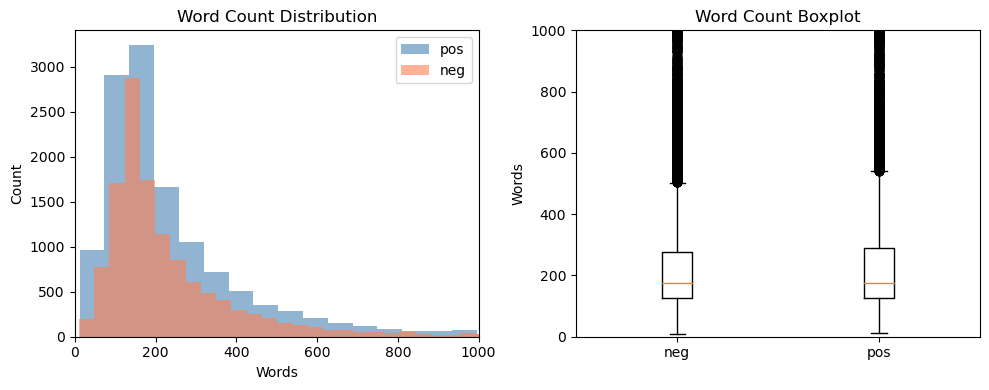

In [5]:
df_train["word_count"] = df_train["text"].apply(lambda x: len(x.split()))
df_test["word_count"] = df_test["text"].apply(lambda x: len(x.split()))

display(df_train["word_count"].describe().to_frame().T)
display(df_train.groupby("label")["word_count"].describe())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df_train[df_train["label"] == "pos"]["word_count"], bins=40, alpha=0.6, color="steelblue", label="pos")
axes[0].hist(df_train[df_train["label"] == "neg"]["word_count"], bins=40, alpha=0.6, color="coral", label="neg")
axes[0].set_title("Word Count Distribution")
axes[0].set_xlabel("Words")
axes[0].set_ylabel("Count")
axes[0].set_xlim(0, 1000)
axes[0].legend()

try:
    axes[1].boxplot([df_train[df_train["label"] == "neg"]["word_count"], df_train[df_train["label"] == "pos"]["word_count"]], tick_labels=["neg", "pos"])
except TypeError:
    axes[1].boxplot([df_train[df_train["label"] == "neg"]["word_count"], df_train[df_train["label"] == "pos"]["word_count"]], labels=["neg", "pos"])
axes[1].set_title("Word Count Boxplot")
axes[1].set_ylabel("Words")
axes[1].set_ylim(0, 1000)

plt.tight_layout()
plt.show()


**Nhận xét:**
- Độ dài văn bản có phân phối lệch phải (right-skewed), tập trung chủ yếu từ 127 đến 284 từ, trung vị là 174 từ, bài dài nhất lên tới 2,470 từ.
- So sánh giữa 2 lớp: review tích cực (`pos`) có trung bình 236.7 từ, review tiêu cực (`neg`) có trung bình 230.9 từ, trung vị của cả hai lớp đều là 174 từ.
- Phân phối độ dài giữa review khen và chê gần như tương đương nhau, do đó độ dài văn bản không phải là đặc trưng dùng để phân loại nhãn cảm xúc.


## 12. Data Leakage và phân chia dữ liệu Train / Val / Test

In [6]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

split_dir = "datasets/splits"
if not os.path.exists(split_dir) and os.path.exists(os.path.join("lab04", split_dir)):
    split_dir = os.path.join("lab04", split_dir)

train_path = os.path.join(split_dir, "train.csv")
val_path = os.path.join(split_dir, "val.csv")
test_path = os.path.join(split_dir, "test.csv")

if os.path.exists(train_path) and os.path.exists(val_path) and os.path.exists(test_path):
    df_train = pd.read_csv(train_path)
    df_val = pd.read_csv(val_path)
    df_test = pd.read_csv(test_path)
else:
    df_all = pd.concat([load_imdb("train"), load_imdb("test")], ignore_index=True)
    df_dedup = df_all.drop_duplicates(subset=["text"]).reset_index(drop=True)
    
    df_train, df_temp = train_test_split(df_dedup, test_size=0.30, random_state=42, stratify=df_dedup["label"])
    df_val, df_test = train_test_split(df_temp, test_size=0.50, random_state=42, stratify=df_temp["label"])
    
    os.makedirs(split_dir, exist_ok=True)
    df_train.to_csv(train_path, index=False)
    df_val.to_csv(val_path, index=False)
    df_test.to_csv(test_path, index=False)

split_summary = pd.DataFrame({
    "Tập dữ liệu": ["Train (70%)", "Validation (15%)", "Test (15%)"],
    "Số lượng mẫu": [len(df_train), len(df_val), len(df_test)],
    "Số mẫu pos": [(df_train["label"] == "pos").sum(), (df_val["label"] == "pos").sum(), (df_test["label"] == "pos").sum()],
    "Số mẫu neg": [(df_train["label"] == "neg").sum(), (df_val["label"] == "neg").sum(), (df_test["label"] == "neg").sum()]
})
display(split_summary)

,Tập dữ liệu,Số lượng mẫu,Số mẫu pos,Số mẫu neg
0,Train (70%),34707,17419,17288
1,Validation (15%),7437,3732,3705
2,Test (15%),7438,3733,3705


In [7]:
overlap_train_val = len(set(df_train["text"]).intersection(set(df_val["text"])))
overlap_train_test = len(set(df_train["text"]).intersection(set(df_test["text"])))
overlap_val_test = len(set(df_val["text"]).intersection(set(df_test["text"])))

leakage_df = pd.DataFrame({
    "Cặp tập dữ liệu": ["Train - Validation", "Train - Test", "Validation - Test"],
    "Số mẫu trùng lặp": [overlap_train_val, overlap_train_test, overlap_val_test],
    "Trạng thái Data Leakage": ["An toàn (0 mẫu)" if x == 0 else f"Cảnh báo ({x} mẫu)" for x in [overlap_train_val, overlap_train_test, overlap_val_test]]
})
display(leakage_df)

,Cặp tập dữ liệu,Số mẫu trùng lặp,Trạng thái Data Leakage
0,Train - Validation,0,An toàn (0 mẫu)
1,Train - Test,0,An toàn (0 mẫu)
2,Validation - Test,0,An toàn (0 mẫu)


Nhận xét:

Bộ dữ liệu aclImdb ban đầu tồn tại 123 mẫu trùng lặp giữa hai tập train và test cùng nhiều bài trùng lặp nội bộ. Nếu tiến hành chia tập trực tiếp mà không lọc trùng, các bài đánh giá giống hệt nhau sẽ phân tán vào cả tập train lẫn val và test, gây ra hiện tượng rò rỉ dữ liệu khiến kết quả đánh giá mô hình bị lạc quan giả tạo. Sau khi loại bỏ 418 mẫu trùng lặp, tập dữ liệu còn lại 49.582 bài viết độc nhất.

Quá trình phân chia theo tỷ lệ 70% train, 15% validation và 15% test bằng phương pháp phân tầng mang lại 34.707 mẫu train, 7.437 mẫu val và 7.438 mẫu test. Kết quả kiểm tra đối sánh văn bản giữa các cặp tập dữ liệu đều trả về 0, chứng minh không còn bất kỳ sự giao thoa hay rò rỉ dữ liệu nào giữa các tập. Đồng thời, tỷ lệ giữa hai nhãn pos và neg ở cả ba tập đều được bảo toàn ở mức xấp xỉ 50% - 50%, đảm bảo tính cân bằng cho bài toán phân loại.

Các tập dữ liệu đã được lưu trữ cố định dưới dạng csv, giúp các bước tiền xử lý và huấn luyện mô hình phía sau có thể nạp dữ liệu trực tiếp trong chưa đầy một giây thay vì phải duyệt lại hàng chục nghìn tệp văn bản từ đầu.

## Experiment 2 — Baseline Model (TF-IDF + Logistic Regression)

In [8]:
import os
import sys
import time
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

for p in [".", "lab04"]:
    if p not in sys.path:
        sys.path.append(p)

from preprocessing import clean_text

df_train["clean_text"] = df_train["text"].apply(clean_text)
df_val["clean_text"] = df_val["text"].apply(clean_text)
df_test["clean_text"] = df_test["text"].apply(clean_text)

In [9]:
start_time = time.time()

vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(df_train["clean_text"])
X_val = vectorizer.transform(df_val["clean_text"])
X_test = vectorizer.transform(df_test["clean_text"])

y_train = (df_train["label"] == "pos").astype(int).values
y_val = (df_val["label"] == "pos").astype(int).values
y_test = (df_test["label"] == "pos").astype(int).values

clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train)

train_time = time.time() - start_time
vocab_size = len(vectorizer.vocabulary_)

In [10]:
y_val_pred = clf.predict(X_val)
y_test_pred = clf.predict(X_test)

results = pd.DataFrame([
    {
        "Representation": "TF-IDF",
        "Classifier": "Logistic Regression (Validation)",
        "Accuracy": round(accuracy_score(y_val, y_val_pred), 4),
        "Precision": round(precision_score(y_val, y_val_pred), 4),
        "Recall": round(recall_score(y_val, y_val_pred), 4),
        "F1": round(f1_score(y_val, y_val_pred), 4)
    },
    {
        "Representation": "TF-IDF",
        "Classifier": "Logistic Regression (Test)",
        "Accuracy": round(accuracy_score(y_test, y_test_pred), 4),
        "Precision": round(precision_score(y_test, y_test_pred), 4),
        "Recall": round(recall_score(y_test, y_test_pred), 4),
        "F1": round(f1_score(y_test, y_test_pred), 4)
    }
])
display(results)

print(classification_report(y_test, y_test_pred, target_names=["neg", "pos"], digits=4))

,Representation,Classifier,Accuracy,Precision,Recall,F1
0,TF-IDF,Logistic Regression (Validation),0.8977,0.8878,0.9113,0.8994
1,TF-IDF,Logistic Regression (Test),0.9016,0.8952,0.9105,0.9028


              precision    recall  f1-score   support

         neg     0.9083    0.8926    0.9004      3705
         pos     0.8952    0.9105    0.9028      3733

    accuracy                         0.9016      7438
   macro avg     0.9017    0.9016    0.9016      7438
weighted avg     0.9017    0.9016    0.9016      7438



## Experiment 3 — Representation Comparison

In [11]:
import sys
import os
import time
import warnings
import numpy as np
from gensim.models import Word2Vec

warnings.filterwarnings("ignore")
sys.unraisablehook = lambda u: None

train_tokens = [t.split() for t in df_train["clean_text"]]
val_tokens = [t.split() for t in df_val["clean_text"]]
test_tokens = [t.split() for t in df_test["clean_text"]]

w2v_start = time.time()
w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10,
    seed=42
)
w2v_train_time = time.time() - w2v_start

def get_doc_vector(tokens, model, dim=100):
    vecs = [model.wv[w] for w in tokens if w in model.wv]
    if len(vecs) == 0:
        return np.zeros(dim)
    return np.mean(vecs, axis=0)

X_train_w2v = np.array([get_doc_vector(t, w2v_model) for t in train_tokens])
X_val_w2v = np.array([get_doc_vector(t, w2v_model) for t in val_tokens])
X_test_w2v = np.array([get_doc_vector(t, w2v_model) for t in test_tokens])

In [12]:
from sklearn.svm import LinearSVC

clf_w2v = LogisticRegression(max_iter=1000, random_state=42)
clf_w2v.fit(X_train_w2v, y_train)

y_val_pred_w2v = clf_w2v.predict(X_val_w2v)
y_test_pred_w2v = clf_w2v.predict(X_test_w2v)

clf_svm = LinearSVC(random_state=42, max_iter=2000)
clf_svm.fit(X_train, y_train)

y_val_pred_svm = clf_svm.predict(X_val)
y_test_pred_svm = clf_svm.predict(X_test)

In [13]:
exp3_results = pd.DataFrame([
    {
        "Representation": "TF-IDF",
        "Classifier": "Logistic Regression",
        "Accuracy": round(accuracy_score(y_test, y_test_pred), 4),
        "Precision": round(precision_score(y_test, y_test_pred), 4),
        "Recall": round(recall_score(y_test, y_test_pred), 4),
        "F1": round(f1_score(y_test, y_test_pred), 4)
    },
    {
        "Representation": "Avg Word2Vec",
        "Classifier": "Logistic Regression",
        "Accuracy": round(accuracy_score(y_test, y_test_pred_w2v), 4),
        "Precision": round(precision_score(y_test, y_test_pred_w2v), 4),
        "Recall": round(recall_score(y_test, y_test_pred_w2v), 4),
        "F1": round(f1_score(y_test, y_test_pred_w2v), 4)
    },
    {
        "Representation": "TF-IDF",
        "Classifier": "Linear SVM",
        "Accuracy": round(accuracy_score(y_test, y_test_pred_svm), 4),
        "Precision": round(precision_score(y_test, y_test_pred_svm), 4),
        "Recall": round(recall_score(y_test, y_test_pred_svm), 4),
        "F1": round(f1_score(y_test, y_test_pred_svm), 4)
    }
])
display(exp3_results)

results_csv_path = "results.csv" if not os.path.exists("lab04") else "lab04/results.csv"
exp3_results.to_csv(results_csv_path, index=False)

,Representation,Classifier,Accuracy,Precision,Recall,F1
0,TF-IDF,Logistic Regression,0.9016,0.8952,0.9105,0.9028
1,Avg Word2Vec,Logistic Regression,0.8428,0.8368,0.8532,0.8449
2,TF-IDF,Linear SVM,0.9060,0.9011,0.9129,0.9070


## Experiment 4 — Word Order & Negation

In [14]:
from sklearn.metrics.pairwise import cosine_similarity

s1 = "this movie is good"
s2 = "this movie is not good"

v1 = get_doc_vector(s1.split(), w2v_model)
v2 = get_doc_vector(s2.split(), w2v_model)

w2v_sim = cosine_similarity([v1], [v2])[0][0]

v1_tfidf = vectorizer.transform([s1])
v2_tfidf = vectorizer.transform([s2])
tfidf_sim = cosine_similarity(v1_tfidf, v2_tfidf)[0][0]

p1_w2v = clf_w2v.predict_proba([v1])[0][1]
p2_w2v = clf_w2v.predict_proba([v2])[0][1]

p1_tfidf = clf.predict_proba(v1_tfidf)[0][1]
p2_tfidf = clf.predict_proba(v2_tfidf)[0][1]

exp4_df = pd.DataFrame([
    {
        "Sentence": s1,
        "True Label": "pos",
        "W2V P(pos)": round(p1_w2v, 4),
        "W2V Pred": "pos" if p1_w2v >= 0.5 else "neg",
        "TF-IDF P(pos)": round(p1_tfidf, 4),
        "TF-IDF Pred": "pos" if p1_tfidf >= 0.5 else "neg"
    },
    {
        "Sentence": s2,
        "True Label": "neg",
        "W2V P(pos)": round(p2_w2v, 4),
        "W2V Pred": "pos" if p2_w2v >= 0.5 else "neg",
        "TF-IDF P(pos)": round(p2_tfidf, 4),
        "TF-IDF Pred": "pos" if p2_tfidf >= 0.5 else "neg"
    }
])
display(exp4_df)

sim_df = pd.DataFrame([
    {"Representation": "Average Word2Vec", "Cosine Similarity": round(w2v_sim, 4)},
    {"Representation": "TF-IDF (Unigram)", "Cosine Similarity": round(tfidf_sim, 4)}
])
display(sim_df)

,Sentence,True Label,W2V P(pos),W2V Pred,TF-IDF P(pos),TF-IDF Pred
0,this movie is good,pos,0.9903,pos,0.8716,pos
1,this movie is not good,neg,0.8520,pos,0.6319,pos


,Representation,Cosine Similarity
0,Average Word2Vec,0.9385
1,TF-IDF (Unigram),0.8875


## Experiment 5 — N-gram Features

In [15]:
start_time = time.time()
vec_bigram = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_train_bigram = vec_bigram.fit_transform(df_train["clean_text"])
X_test_bigram = vec_bigram.transform(df_test["clean_text"])

clf_bigram = LogisticRegression(max_iter=1000, random_state=42)
clf_bigram.fit(X_train_bigram, y_train)
bigram_time = time.time() - start_time

y_test_pred_bigram = clf_bigram.predict(X_test_bigram)
bigram_vocab = len(vec_bigram.vocabulary_)

exp5_results = pd.DataFrame([
    {
        "Features": "Unigram",
        "Vocabulary": f"{vocab_size:,}",
        "Training Time (s)": round(train_time, 2),
        "Accuracy": round(accuracy_score(y_test, y_test_pred), 4),
        "F1": round(f1_score(y_test, y_test_pred), 4)
    },
    {
        "Features": "Unigram + Bigram",
        "Vocabulary": f"{bigram_vocab:,}",
        "Training Time (s)": round(bigram_time, 2),
        "Accuracy": round(accuracy_score(y_test, y_test_pred_bigram), 4),
        "F1": round(f1_score(y_test, y_test_pred_bigram), 4)
    }
])
display(exp5_results)

results_csv_path = "results.csv" if not os.path.exists("lab04") else "lab04/results.csv"
bigram_row = pd.DataFrame([{
    "Representation": "TF-IDF (Uni+Bigram)",
    "Classifier": "Logistic Regression",
    "Accuracy": round(accuracy_score(y_test, y_test_pred_bigram), 4),
    "Precision": round(precision_score(y_test, y_test_pred_bigram), 4),
    "Recall": round(recall_score(y_test, y_test_pred_bigram), 4),
    "F1": round(f1_score(y_test, y_test_pred_bigram), 4)
}])
all_results = pd.concat([pd.read_csv(results_csv_path), bigram_row], ignore_index=True)
all_results.drop_duplicates(subset=["Representation", "Classifier"], keep="last").to_csv(results_csv_path, index=False)

,Features,Vocabulary,Training Time (s),Accuracy,F1
0,Unigram,"87,734",8.63,0.9016,0.9028
1,Unigram + Bigram,"555,050",29.55,0.9062,0.9074


## Model Interpretability — Inspect Model Weights

In [16]:
feature_names = np.array(vectorizer.get_feature_names_out())
coefs = clf.coef_[0]

top_pos_idx = np.argsort(coefs)[-10:][::-1]
top_neg_idx = np.argsort(coefs)[:10]

top_weights_df = pd.DataFrame({
    "Top Positive": feature_names[top_pos_idx],
    "Pos Weight": np.round(coefs[top_pos_idx], 4),
    "Top Negative": feature_names[top_neg_idx],
    "Neg Weight": np.round(coefs[top_neg_idx], 4)
})
display(top_weights_df)

,Top Positive,Pos Weight,Top Negative,Neg Weight
0,great,8.6897,worst,-10.4709
1,excellent,7.0723,bad,-8.8412
2,best,5.7367,awful,-7.9578
3,perfect,5.3229,waste,-7.1522
4,wonderful,4.9970,boring,-6.8689
5,amazing,4.7278,terrible,-6.3798
6,today,4.5698,poor,-6.3633
7,brilliant,4.4224,nothing,-5.4188
8,loved,4.2614,horrible,-5.1782
9,well,4.2552,worse,-5.0219


## Confusion Matrix & Error Analysis

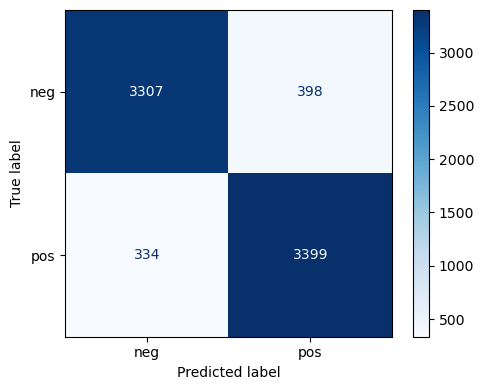

,Index,True Label,Predicted,Snippet
0,0,pos,pos,This was truly a deeply moving movie in every ...
1,1,pos,pos,It's nice to see a film with real people with ...
2,2,pos,pos,Buddy is an entertaining family film set in a ...
3,3,pos,neg,"Okay, here's the deal. There's this American p..."
4,4,pos,neg,If in the 90's you're adapting a book written ...
5,5,neg,pos,THE KING MAKER will doubtless be a success in ...


In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["neg", "pos"])

fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.tight_layout()

cm_path = "confusion_matrix.png" if not os.path.exists("lab04") else "lab04/confusion_matrix.png"
plt.savefig(cm_path, dpi=300)
plt.show()

df_test["predicted"] = ["pos" if p == 1 else "neg" for p in y_test_pred]

correct_samples = df_test[df_test["label"] == df_test["predicted"]].head(3)
wrong_samples = df_test[df_test["label"] != df_test["predicted"]].head(3)

analysis_samples = pd.concat([correct_samples, wrong_samples], ignore_index=True)
analysis_table = pd.DataFrame({
    "Index": analysis_samples.index,
    "True Label": analysis_samples["label"],
    "Predicted": analysis_samples["predicted"],
    "Snippet": analysis_samples["text"].apply(lambda t: t[:120] + "...")
})
display(analysis_table)